In [1]:
! pip install opencv-python
! pip install torch
! pip install ultralytics

In [3]:
# --- Imports ---
import os
from ultralytics import YOLO
import torch
import cv2
import matplotlib.pyplot as plt
import yaml
import shutil
from IPython.display import display
from PIL import Image

# --- Define Project Paths ---
ROOT_DIR = '/Users/juju/Desktop'
RESULTS_DIR = os.path.join(ROOT_DIR, 'results')
DATASET_DIR = ROOT_DIR
DATA_YAML_PATH = os.path.join(ROOT_DIR, 'animal-classification-tima', 'data.yaml')
TEST_DIR = os.path.join(ROOT_DIR, 'animal-classification-tima', 'test', 'images')
TRAIN_DIR = os.path.join(ROOT_DIR, 'animal-classification-tima', 'train', 'images')
VALID_DIR = os.path.join(ROOT_DIR, 'animal-classification-tima', 'valid', 'images')
WEIGHTS_DIR = os.path.join(RESULTS_DIR, 'yolov8_training', 'weights') # To be created during training


# --- Load Data Configuration ---

with open(DATA_YAML_PATH, 'r') as f:
        data_config = yaml.safe_load(f)
        print(f"\nData configuration loaded from: {DATA_YAML_PATH}")
        print("Number of classes:", data_config.get('nc'))
        print("Class names:", data_config.get('names'))


Data configuration loaded from: /Users/juju/Desktop/animal-classification-tima/data.yaml
Number of classes: 80
Class names: ['Bear', 'Brown-bear', 'Bull', 'Butterfly', 'Camel', 'Canary', 'Caterpillar', 'Cattle', 'Centipede', 'Cheetah', 'Chicken', 'Crab', 'Crocodile', 'Deer', 'Duck', 'Eagle', 'Elephant', 'Fish', 'Fox', 'Frog', 'Giraffe', 'Goat', 'Goldfish', 'Goose', 'Hamster', 'Harbor-seal', 'Hedgehog', 'Hippopotamus', 'Horse', 'Jaguar', 'Jellyfish', 'Kangaroo', 'Koala', 'Ladybug', 'Leopard', 'Lion', 'Lizard', 'Lynx', 'Magpie', 'Monkey', 'Moths-and-butterflies', 'Mouse', 'Mule', 'Ostrich', 'Otter', 'Owl', 'Panda', 'Parrot', 'Penguin', 'Pig', 'Polar-bear', 'Rabbit', 'Raccoon', 'Raven', 'Red-panda', 'Rhinoceros', 'Scorpion', 'Sea-lion', 'Sea-turtle', 'Seahorse', 'Shark', 'Sheep', 'Shrimp', 'Snail', 'Snake', 'Sparrow', 'Spider', 'Squid', 'Squirrel', 'Starfish', 'Swan', 'Tick', 'Tiger', 'Tortoise', 'Turkey', 'Turtle', 'Whale', 'Woodpecker', 'Worm', 'Zebra']


In [5]:
# --- Training the model ---
EPOCHS = 20  
IMG_SIZE = 320
MODEL_SIZE = 'yolov8s.pt' 
# --- Initialize YOLO Model ---
model = YOLO(MODEL_SIZE)
print(f"\nUsing pre-trained model: {MODEL_SIZE}")

# --- Train the Model ---
print("\n--- Starting Model Training ---")
train_results = model.train(data=DATA_YAML_PATH,
                            epochs=EPOCHS,
                            imgsz=IMG_SIZE,
                            project=RESULTS_DIR,
                            name='yolov8_training')
print("\n--- Model Training Finished ---")


Using pre-trained model: yolov8s.pt

--- Starting Model Training ---
Ultralytics 8.3.113 🚀 Python-3.12.7 torch-2.6.0 CPU (Apple M2)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/Users/juju/Desktop/animal-classification-tima/data.yaml, epochs=20, time=None, patience=100, batch=16, imgsz=320, save=True, save_period=-1, cache=False, device=None, workers=8, project=/Users/juju/Desktop/results, name=yolov8_training2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False

train: Scanning /Users/juju/Desktop/animal-classification-tima/train/labels.cach

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 223.1±98.4 MB/s, size: 87.6 KB)



val: Scanning /Users/juju/Desktop/animal-classification-tima/valid/labels.cache.


Plotting labels to /Users/juju/Desktop/results/yolov8_training2/labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000119, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Image sizes 320 train, 320 val
Using 0 dataloader workers
Logging results to /Users/juju/Desktop/results/yolov8_training2
Starting training for 20 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...


      20/20         0G     0.5448     0.6253     0.9576         16        320: 1
                 Class     Images  Instances      Box(P          R      mAP50  m

                   all        593        712      0.387      0.436      0.418      0.354

20 epochs completed in 4.723 hours.


Optimizer stripped from /Users/juju/Desktop/results/yolov8_training2/weights/last.pt, 22.5MB
Optimizer stripped from /Users/juju/Desktop/results/yolov8_training2/weights/best.pt, 22.5MB

Validating /Users/juju/Desktop/results/yolov8_training2/weights/best.pt...
Ultralytics 8.3.113 🚀 Python-3.12.7 torch-2.6.0 CPU (Apple M2)
Model summary (fused): 72 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  m


                   all        593        712      0.481      0.426       0.43      0.364
                  Bear          5          5      0.596        0.2      0.216      0.195
            Brown-bear          1          1       0.11          1      0.166      0.166
                  Bull          2          4      0.957          1      0.995      0.921
             Butterfly         40         47      0.438      0.723      0.632      0.421
                Canary          3          6      0.458      0.333      0.286      0.246
           Caterpillar         13         13      0.206     0.0769      0.165      0.106
                Cattle          4          4      0.336       0.75      0.759       0.75
             Centipede          6          6      0.655      0.333       0.47      0.268
               Cheetah          7          7      0.387      0.143      0.258      0.215
               Chicken          7          8      0.658      0.875       0.85      0.637
                  Cra

In [7]:
import json
from ultralytics import YOLO

model = YOLO('yolov8s.pt')  

def analyze_wildlife(image_path):
    # Perform inference
    results = model(image_path)

    detections = []
    for result in results:
        for box in result.boxes:
            cls_id = int(box.cls[0])
            confidence = float(box.conf[0])
            bbox = box.xyxy[0].tolist()  # [x1, y1, x2, y2]

            class_name = model.names[cls_id]

            if '_' in class_name:
                species, individual = class_name.split('_', 1)
            else:
                species = class_name
                individual = None

            is_poaching = "poaching" in species.lower() or species.lower() in {'human', 'gun', 'trap'}

            detections.append({
                'species': species,
                'individual_id': individual,
                'confidence': confidence,
                'bounding_box': [round(x, 2) for x in bbox],
                'poaching_activity': is_poaching
            })

    return detections

if __name__ == "__main__":
    image_path = "/Users/juju/Desktop/Project dataset/test/images"  
    results = analyze_wildlife(image_path)

    print(json.dumps(results, indent=2))

    with open('results.json', 'w') as f:
        json.dump(results, f, indent=2)


image 1/297 /Users/juju/Desktop/Project dataset/test/images/0006476c7a10ac38_jpg.rf.e51a049c91f92fc0dfbcb76fcf5bb97b.jpg: 640x480 2 horses, 102.3ms
image 2/297 /Users/juju/Desktop/Project dataset/test/images/00e0901b0370cf38_jpg.rf.956242fc3a212705813ba87117b7e412.jpg: 480x640 1 bird, 98.1ms
image 3/297 /Users/juju/Desktop/Project dataset/test/images/00eeb20f84060e72_jpg.rf.da39918fcb5dbecd4dbe22f5259be061.jpg: 480x640 1 horse, 1 elephant, 94.7ms
image 4/297 /Users/juju/Desktop/Project dataset/test/images/00eeeb9233846b7c_jpg.rf.6df93831e4f7755835b26c69a690fd8c.jpg: 640x448 1 bird, 89.3ms
image 5/297 /Users/juju/Desktop/Project dataset/test/images/01650042709e7a82_jpg.rf.4a50eb504414ee51cecabcb327dff12c.jpg: 448x640 1 bear, 86.4ms
image 6/297 /Users/juju/Desktop/Project dataset/test/images/016e7365231c513c_jpg.rf.81a75f18fc760b117f5b4acdcdd0438f.jpg: 544x640 1 sheep, 118.7ms
image 7/297 /Users/juju/Desktop/Project dataset/test/images/01a19962b9645080_jpg.rf.e2b5fcf1177cdffec9a7d79d6f6


image 1/1 /Users/juju/Desktop/Discussion pics/3 animals.jpeg: 224x320 3 Giraffes, 1 Rhinoceros, 3 Zebras, 30.9ms
Speed: 0.6ms preprocess, 30.9ms inference, 0.6ms postprocess per image at shape (1, 3, 224, 320)
Displaying image 1...


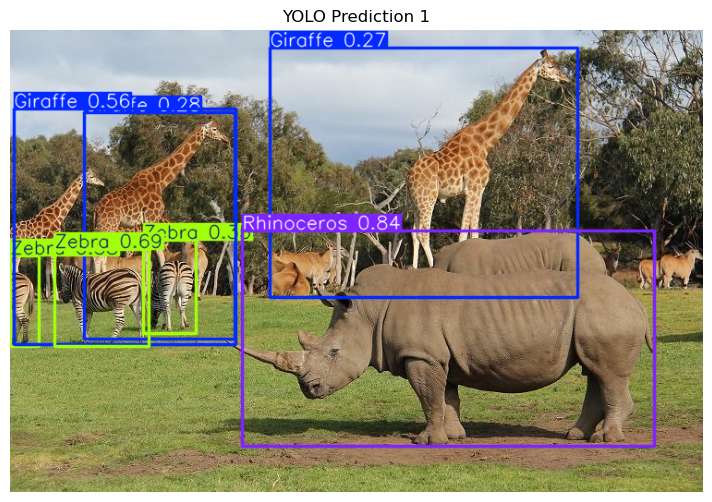

In [169]:
#you give the image path and he gives you the image and the name of the class it belongs to
#bonus varying lightning #bonus more than one species detected simultaneously 
import os
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

WEIGHTS_PATH = '/Users/juju/Desktop/results/yolov8_training2/weights/best.pt'
image_path = '/Users/juju/Desktop/Discussion pics/3 animals.jpeg'
model = YOLO(WEIGHTS_PATH)

results = model.predict(source=image_path)


for i, result in enumerate(results):
    print(f"Displaying image {i+1}...")

    img_bgr = result.plot()
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Show image
    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"YOLO Prediction {i+1}")
    plt.show()

    # Save annotated image
    image_name = os.path.basename(image_path)
    


image 1/1 /Users/juju/Desktop/Project dataset/test/images/16904f24c2242b70_jpg.rf.f59816a37e68fa9bcc30434cd9ff232b.jpg: 224x320 1 Centipede, 31.2ms
Speed: 0.4ms preprocess, 31.2ms inference, 0.3ms postprocess per image at shape (1, 3, 224, 320)
Displaying image 1...


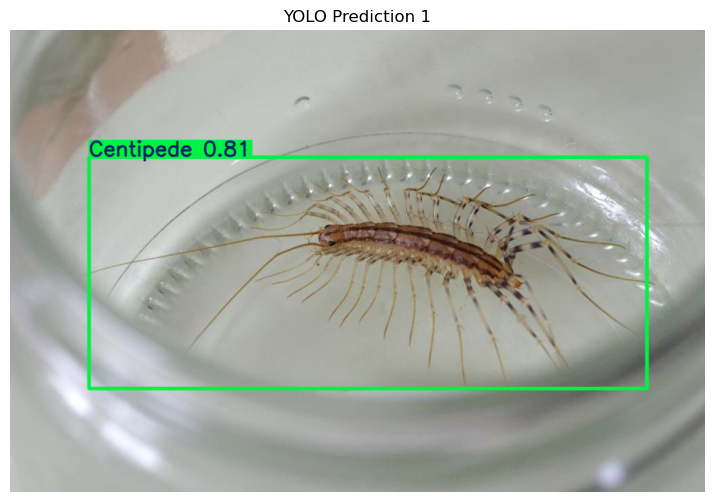

In [177]:
#Random he gives you a random image of animal and his name
import os
import random
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

WEIGHTS_PATH = '/Users/juju/Desktop/results/yolov8_training2/weights/best.pt'
TEST_IMAGES_DIR = '/Users/juju/Desktop/Project dataset/test/images'
OUTPUT_DIR = '/Users/juju/Desktop/results/random'
os.makedirs(OUTPUT_DIR, exist_ok=True)

model = YOLO(WEIGHTS_PATH)
test_images = [f for f in os.listdir(TEST_IMAGES_DIR) if f.endswith(('.jpg', '.jpeg', '.png'))]

random_image_name = random.choice(test_images)
random_image_path = os.path.join(TEST_IMAGES_DIR, random_image_name)

results = model.predict(source=random_image_path)
for i, result in enumerate(results):
    print(f"Displaying image {i+1}...")

    img_bgr = result.plot()
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"YOLO Prediction {i+1}")
    plt.show()

    output_path = os.path.join(OUTPUT_DIR, f"predicted_{random_image_name}")
    cv2.imwrite(output_path, cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))


image 1/1 /Users/juju/Desktop/Discussion pics/grain1.jpeg: 224x320 3 Zebras, 34.1ms
Speed: 0.3ms preprocess, 34.1ms inference, 0.3ms postprocess per image at shape (1, 3, 224, 320)
Displaying image 1...


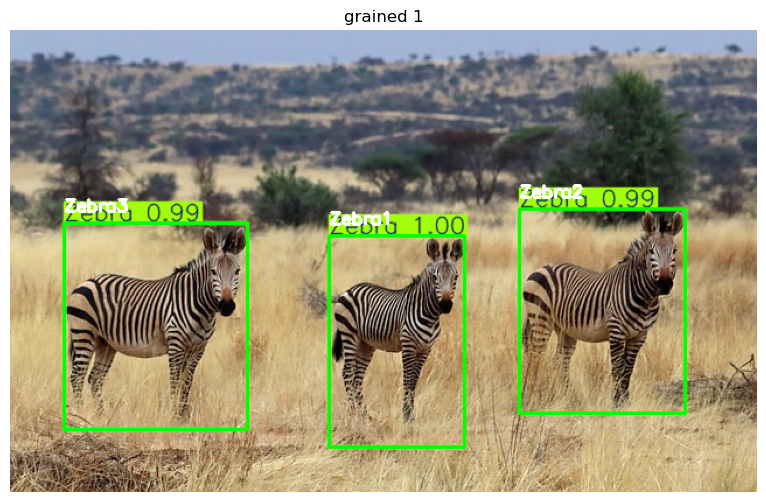

In [171]:
#bonus graining
import os
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from collections import defaultdict

WEIGHTS_PATH ='/Users/juju/Desktop/results/yolov8_training2/weights/best.pt'
image_path = '/Users/juju/Desktop/Discussion pics/grain1.jpeg'
model = YOLO(WEIGHTS_PATH)

results = model.predict(source=image_path)

for i, result in enumerate(results):
    print(f"Displaying image {i+1}...")

    img_bgr = result.plot()
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    class_counts = defaultdict(int)
    
    for box in result.boxes:
        class_id = int(box.cls)  # Get the class ID
        class_name = result.names[class_id]  # Get the class name
        class_counts[class_name] += 1 #increment
        count = class_counts[class_name]
        
        label_text = f"{class_name}{count}"

        xyxy = box.xyxy[0].cpu().numpy()
        x_min, y_min, x_max, y_max = map(int, xyxy)

       
        cv2.rectangle(img_rgb, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)  # Green box
        cv2.putText(img_rgb, label_text, (x_min, y_min - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)  # White text

    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"grained {i+1}")
    plt.show()


0: 256x320 2 Penguins, 30.2ms
Speed: 2.3ms preprocess, 30.2ms inference, 0.7ms postprocess per image at shape (1, 3, 256, 320)
Displaying image 1...


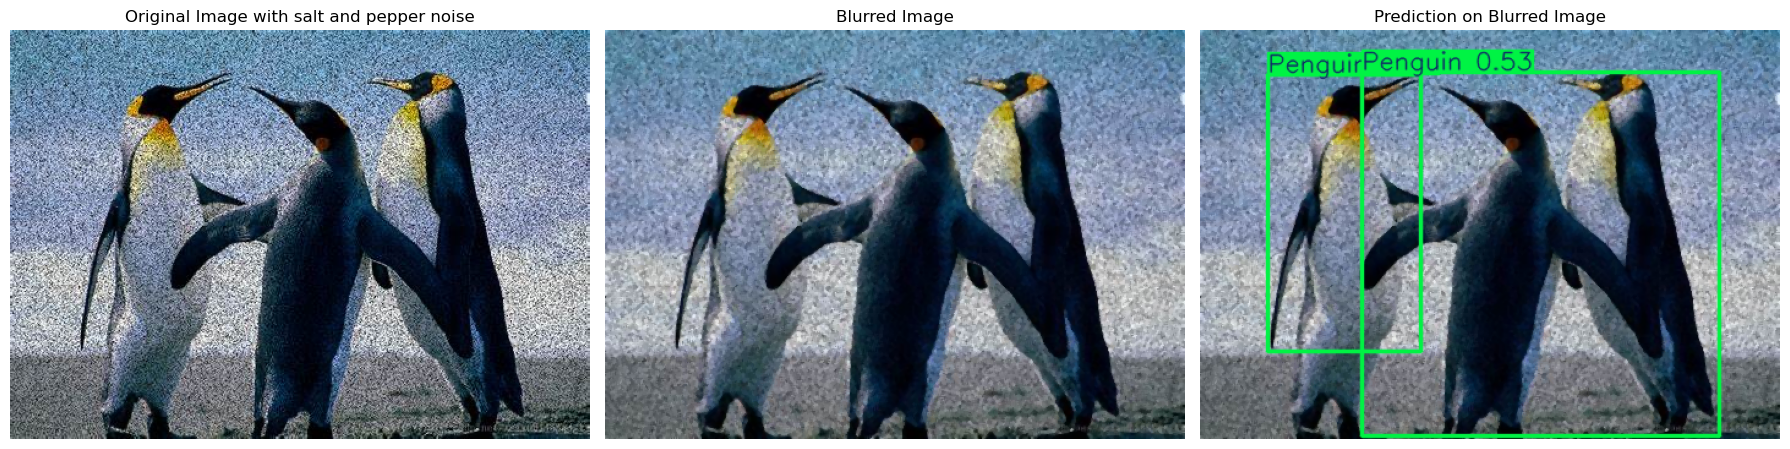

In [112]:
import os
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

WEIGHTS_PATH = '/Users/juju/Desktop/results/yolov8_training2/weights/best.pt'
image_path = '/Users/juju/Desktop/Discussion pics/salt&pepper.jpeg'
model = YOLO(WEIGHTS_PATH)


def apply_median_blur(img):
 
    blurred_img = cv2.medianBlur(img, 3)
    return blurred_img

img_original = cv2.imread(image_path)
img_rgb_original = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

img_blurred = apply_median_blur(img_original)
img_rgb_blurred = cv2.cvtColor(img_blurred, cv2.COLOR_BGR2RGB)

results = model.predict(source=img_blurred)  

for i, result in enumerate(results):
    print(f"Displaying image {i+1}...")
    img_bgr_prediction = result.plot()  
    img_rgb_prediction = cv2.cvtColor(img_bgr_prediction, cv2.COLOR_BGR2RGB)
    
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb_original)
plt.axis('off')
plt.title("Original Image with salt and pepper noise")

plt.subplot(1, 3, 2)
plt.imshow(img_rgb_blurred)
plt.axis('off')
plt.title("Blurred Image")

plt.subplot(1, 3, 3)
plt.imshow(img_rgb_prediction)
plt.axis('off')
plt.title("Prediction on Blurred Image")


plt.tight_layout()
plt.show()